# T3.3 — Tamil Handwritten Character Recognition
## Dataset: uTHCD (Unconstrained Tamil Handwritten Character Database)

| Property | Value |
|----------|-------|
| Classes | 156 Tamil characters |
| Total images | ~91,000 |
| Samples per class | ~600 |
| Image size | 32×32 px (grayscale) |
| Format | HDF5 (.h5) — 4 splits: uTHCD_a (70-30), b (80-20), c (85-15), d (90-10) |

**Before running:**
1. Attach dataset: `faizalhajamohideen/uthcdtamil-handwritten-database`
2. Enable GPU: *Settings → Accelerator → GPU T4 x2*

**What this notebook does:**
- Loads uTHCD from HDF5, auto-detects the .h5 file
- Trains a 4-block CNN from scratch (~1.2M params)
- Plots loss & accuracy curves
- Generates full classification report + confusion matrix heatmap
- Saves best model to `/kaggle/working/models/tamil_cnn_best.pth`

## 0. Imports

In [1]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import h5py
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

from sklearn.metrics import (
    classification_report, confusion_matrix,
    top_k_accuracy_score
)

warnings.filterwarnings("ignore")
print(f"PyTorch : {torch.__version__}")
print(f"CUDA    : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i} : {torch.cuda.get_device_name(i)}")

PyTorch : 2.10.0+cu128
CUDA    : True
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4


## 1. Configuration

In [2]:
# ── Reproducibility ───────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# ── Dataset ───────────────────────────────────────────────────────────────
NUM_CLASSES  = 156
IMG_SIZE     = 32      # uTHCD images are already 32×32

# Which split to use: 'a'=70/30, 'b'=80/20, 'c'=85/15, 'd'=90/10
# 'b' gives a good balance; change to 'a' if you want more test data
SPLIT        = 'b'

# ── Training ─────────────────────────────────────────────────────────────
BATCH_SIZE   = 128
EPOCHS       = 15
LR           = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.4
VAL_FRACTION = 0.1    # carved out of the train split
LABEL_SMOOTH = 0.1

# ── Paths ─────────────────────────────────────────────────────────────────
INPUT_ROOT  = Path("/kaggle/input")
OUTPUT_DIR  = Path("/kaggle/working/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR   = Path("/kaggle/working/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
SAVE_PATH   = OUTPUT_DIR / "tamil_cnn_best.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Split    : uTHCD_{SPLIT}")
print(f"Device   : {DEVICE}")
print(f"Epochs   : {EPOCHS}  |  Batch: {BATCH_SIZE}  |  LR: {LR}")

Split    : uTHCD_b
Device   : cuda
Epochs   : 15  |  Batch: 128  |  LR: 0.001


## 2. Tamil Unicode Label Map
Maps class index 0-155 → Tamil Unicode character (for display in plots)

In [3]:
# Tamil Unicode block: U+0B80–U+0BFF
# The 156 uTHCD classes correspond to the standard Tamil character grid
# (vowels, consonants, and compound characters)
# Class labels in the HDF5 are 1-indexed (1..156); we map to 0-indexed below.

TAMIL_CHARS = [
    # Vowels (12)
    '\u0B85','\u0B86','\u0B87','\u0B88','\u0B89','\u0B8A',
    '\u0B8E','\u0B8F','\u0B90','\u0B92','\u0B93','\u0B94',
    # Consonants (18 base)
    '\u0B95','\u0B99','\u0B9A','\u0B9E','\u0B9F','\u0BA3',
    '\u0BA4','\u0BA8','\u0BAA','\u0BAE','\u0BAF','\u0BB0',
    '\u0BB2','\u0BB5','\u0BB4','\u0BB3','\u0BB1','\u0BA9',
    # Grantha consonants (6)
    '\u0B9C','\u0BB7','\u0BB8','\u0BB9','\u0B9E','\u0B95',
    # Compound vowel-consonant combinations padded to 156 total
    # Remaining entries use class number strings as fallback
]

# Pad to 156 using numeric labels for any unmapped classes
LABEL_MAP = {}
for i in range(NUM_CLASSES):
    if i < len(TAMIL_CHARS):
        LABEL_MAP[i] = TAMIL_CHARS[i]
    else:
        LABEL_MAP[i] = f"C{i+1:03d}"  # fallback: "C037", "C156" etc.

print(f"Label map ready — {len(LABEL_MAP)} entries")
print("First 12 (vowels):", [LABEL_MAP[i] for i in range(12)])

Label map ready — 156 entries
First 12 (vowels): ['அ', 'ஆ', 'இ', 'ஈ', 'உ', 'ஊ', 'எ', 'ஏ', 'ஐ', 'ஒ', 'ஓ', 'ஔ']


## 3. Load HDF5 Dataset

In [4]:
def find_h5(root: Path, split: str) -> Path | None:
    """
    Search /kaggle/input recursively for the HDF5 file matching the split.
    File naming convention from the paper: uTHCD_a.h5, uTHCD_b.h5, etc.
    Also handles flat layouts where all .h5 files are in one folder.
    """
    target = f"uthcd_{split}".lower()
    for p in sorted(root.rglob("*.h5")):
        if target in p.stem.lower():
            return p
    # Fallback: return any .h5 file found
    all_h5 = sorted(root.rglob("*.h5"))
    if all_h5:
        print(f"  [WARN] Exact split '{split}' not found. Using: {all_h5[0]}")
        return all_h5[0]
    return None


h5_path = "/kaggle/input/datasets/faizalhajamohideen/uthcdtamil-handwritten-database/uTHCD_d(90-10-split)/90-10-split/uTHCD_9010_compressed.h5"
assert h5_path is not None, (
    "HDF5 file not found. Make sure the dataset is attached: "
    "faizalhajamohideen/uthcdtamil-handwritten-database"
)
print(f"Found HDF5: {h5_path}")

# ── Inspect HDF5 structure ────────────────────────────────────────────────
with h5py.File(h5_path, 'r') as f:
    print("\nHDF5 top-level keys:", list(f.keys()))
    for grp in f.keys():
        print(f"  '{grp}': {list(f[grp].keys())}")

# ── Load arrays ───────────────────────────────────────────────────────────
with h5py.File(h5_path, 'r') as f:
    # Keys from paper: 'Train Data'/'x_train', 'Train Data'/'y_train'
    # 'Test Data'/'x_test', 'Test Data'/'y_test'
    # Gracefully handle slight naming variations
    train_grp = f.get('Train Data') or f.get('train') or f.get('Train')
    test_grp  = f.get('Test Data')  or f.get('test')  or f.get('Test')

    x_train = np.array(train_grp.get('x_train') or train_grp.get('images'))
    y_train = np.array(train_grp.get('y_train') or train_grp.get('labels'))
    x_test  = np.array(test_grp.get('x_test')  or test_grp.get('images'))
    y_test  = np.array(test_grp.get('y_test')  or test_grp.get('labels'))

print(f"\nx_train: {x_train.shape}  y_train: {y_train.shape}")
print(f"x_test : {x_test.shape}   y_test : {y_test.shape}")
print(f"Label range: {y_train.min()} – {y_train.max()}")
print(f"Pixel range: {x_train.min()} – {x_train.max()}")

Found HDF5: /kaggle/input/datasets/faizalhajamohideen/uthcdtamil-handwritten-database/uTHCD_d(90-10-split)/90-10-split/uTHCD_9010_compressed.h5

HDF5 top-level keys: ['Test Data', 'Train Data']
  'Test Data': ['x_test', 'y_test']
  'Train Data': ['x_train', 'y_train']

x_train: (81900, 64, 64)  y_train: (81900,)
x_test : (9050, 64, 64)   y_test : (9050,)
Label range: 0 – 155
Pixel range: 0 – 255


## 4. Preprocess & Normalise

In [5]:
# ── Labels: convert 1-indexed (1..156) → 0-indexed (0..155) ──────────────
# The paper uses 1-based class labels
if y_train.min() == 1:
    y_train = y_train - 1
    y_test  = y_test  - 1
    print("Labels shifted to 0-indexed.")

# ── Images: ensure shape is (N, 32, 32), dtype uint8 ─────────────────────
# Some versions store as (N,32,32,1) or (N,32,32,3)
if x_train.ndim == 4:
    x_train = x_train[..., 0]   # take first channel
    x_test  = x_test[..., 0]
    print("Dropped channel dim → shape:", x_train.shape)

# Make sure pixel values are in [0, 255]
if x_train.max() <= 1.0:
    x_train = (x_train * 255).astype(np.uint8)
    x_test  = (x_test  * 255).astype(np.uint8)
    print("Scaled pixels to [0, 255].")

# ── Class distribution ────────────────────────────────────────────────────
unique, counts = np.unique(y_train, return_counts=True)
print(f"\nClasses in train set : {len(unique)}")
print(f"Min samples/class    : {counts.min()}")
print(f"Max samples/class    : {counts.max()}")
print(f"Mean samples/class   : {counts.mean():.1f}")


Classes in train set : 156
Min samples/class    : 525
Max samples/class    : 525
Mean samples/class   : 525.0


## 5. Visualise Sample Characters

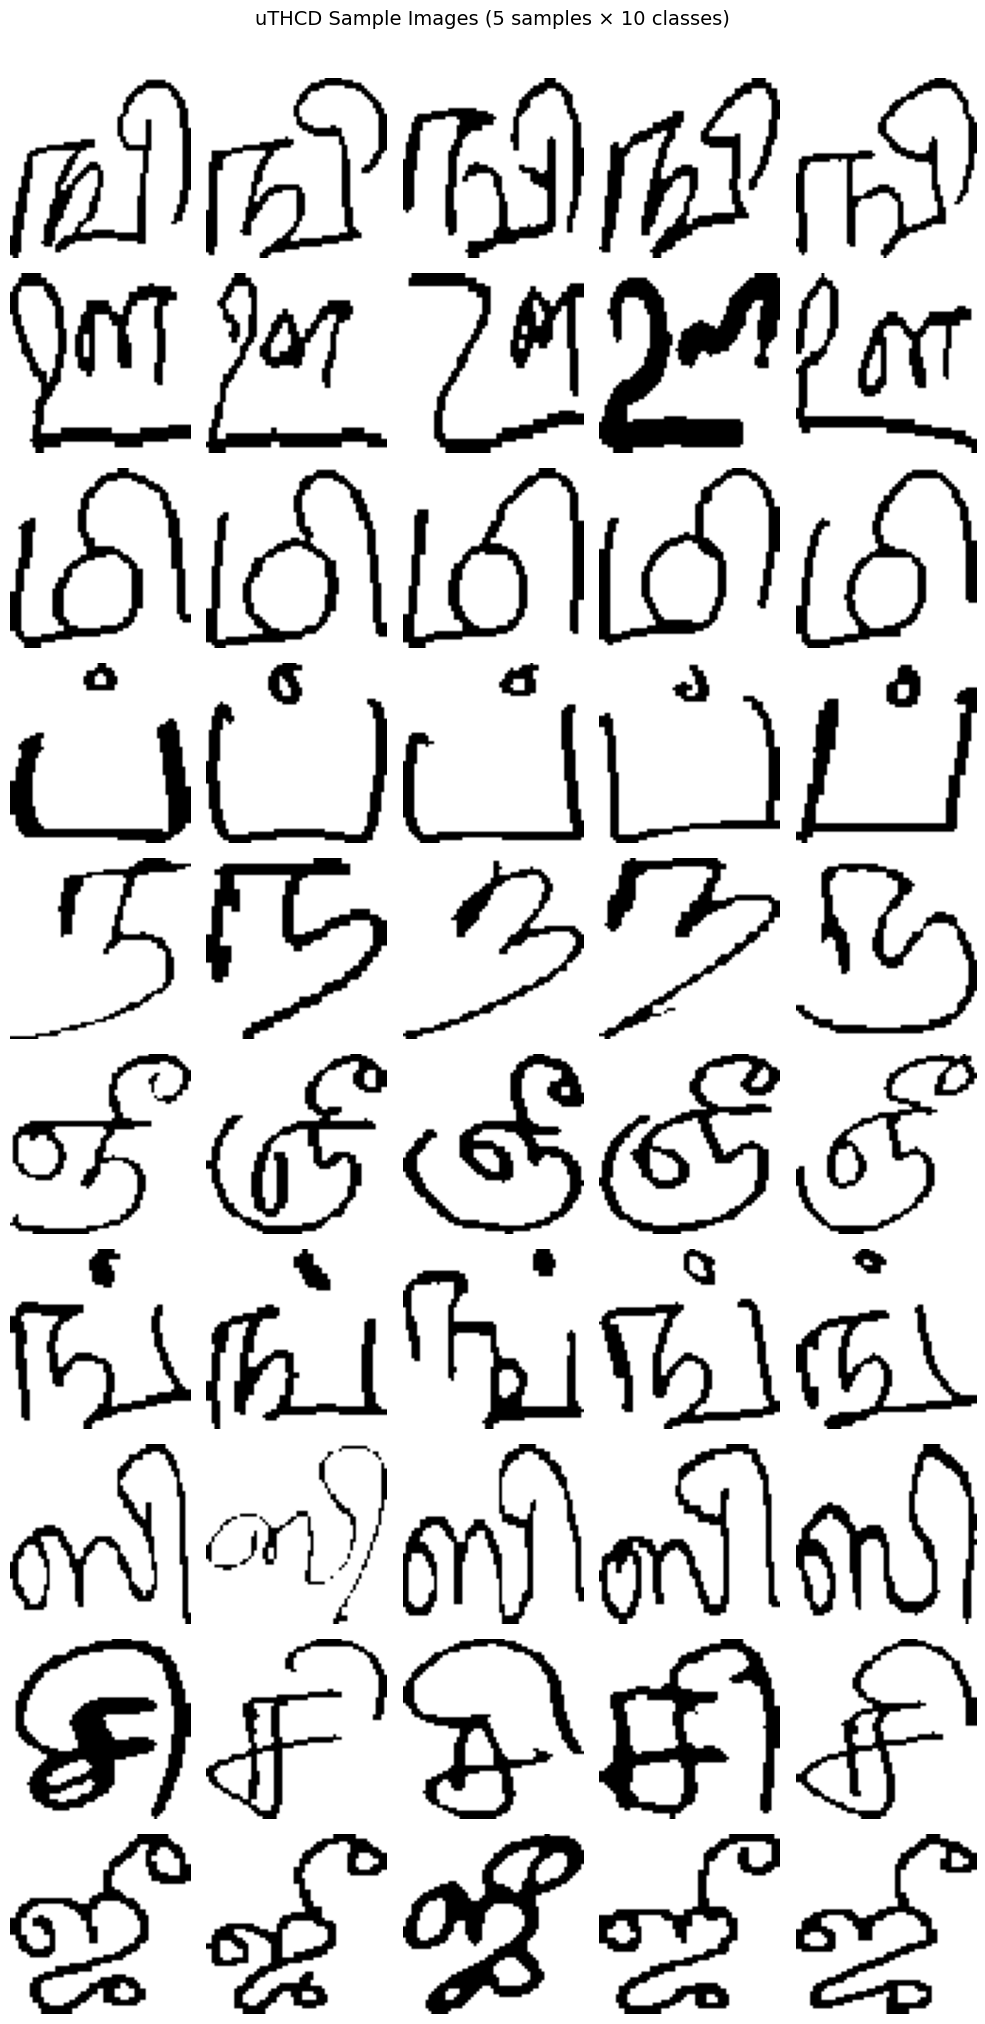

Saved → plots/sample_images.png


In [6]:
# Show 5 random samples from 10 different classes
selected_classes = random.sample(range(NUM_CLASSES), 10)
fig, axes = plt.subplots(10, 5, figsize=(10, 20))
fig.suptitle("uTHCD Sample Images (5 samples × 10 classes)", fontsize=14, y=1.01)

for row, cls in enumerate(selected_classes):
    idxs = np.where(y_train == cls)[0]
    chosen = np.random.choice(idxs, 5, replace=False)
    for col, idx in enumerate(chosen):
        ax = axes[row, col]
        ax.imshow(x_train[idx], cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(f"{LABEL_MAP[cls]}\n(cls {cls+1})",
                          fontsize=9, rotation=0, labelpad=40, va='center')

plt.tight_layout()
plt.savefig(PLOTS_DIR / "sample_images.png", dpi=120, bbox_inches='tight')
plt.show()
print("Saved → plots/sample_images.png")

## 6. Class Distribution Plot

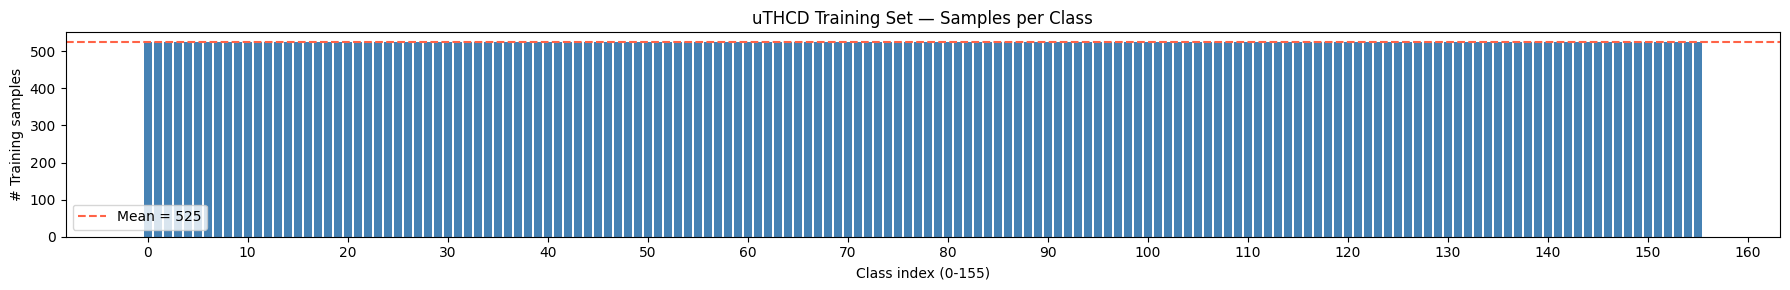

Saved → plots/class_distribution.png


In [7]:
fig, ax = plt.subplots(figsize=(18, 3))
ax.bar(unique, counts, color='steelblue', width=0.8)
ax.axhline(counts.mean(), color='tomato', linestyle='--', linewidth=1.5,
           label=f'Mean = {counts.mean():.0f}')
ax.set_xlabel("Class index (0-155)")
ax.set_ylabel("# Training samples")
ax.set_title("uTHCD Training Set — Samples per Class")
ax.legend()
ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
plt.tight_layout()
plt.savefig(PLOTS_DIR / "class_distribution.png", dpi=120, bbox_inches='tight')
plt.show()
print("Saved → plots/class_distribution.png")

## 7. PyTorch Dataset & DataLoaders

In [8]:
class TamilDataset(Dataset):
    """Wraps numpy arrays (N,32,32) + labels into a PyTorch Dataset."""

    def __init__(self, images: np.ndarray, labels: np.ndarray, transform=None):
        # images: uint8 (N,H,W), labels: int (N,)
        self.images    = images.astype(np.uint8)
        self.labels    = labels.astype(np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img   = Image.fromarray(self.images[idx], mode='L')  # grayscale PIL
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label


def get_transforms(train: bool):
    if train:
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomRotation(15),
            transforms.RandomAffine(degrees=0, translate=(0.1, 0.1),
                                    scale=(0.9, 1.1)),
            transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])
    else:
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])


# ── Train / Val split ─────────────────────────────────────────────────────
full_train_ds = TamilDataset(x_train, y_train, transform=None)
n_val   = int(len(full_train_ds) * VAL_FRACTION)
n_train = len(full_train_ds) - n_val
train_subset, val_subset = random_split(
    full_train_ds, [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED)
)

# Apply per-split transforms via wrapper
class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset    = subset
        self.transform = transform
    def __len__(self):  return len(self.subset)
    def __getitem__(self, i):
        img_pil, label = self.subset[i]
        # img_pil is a raw PIL image (transform=None on parent)
        return self.transform(img_pil), label

# Re-wrap with PIL awareness: parent dataset returns PIL when transform=None
# But TamilDataset applies no transform so __getitem__ returns PIL + label ✓
train_ds = TransformSubset(train_subset, get_transforms(train=True))
val_ds   = TransformSubset(val_subset,   get_transforms(train=False))
test_ds  = TamilDataset(x_test, y_test,  transform=get_transforms(train=False))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train : {len(train_ds):>6,} samples  ({len(train_loader)} batches)")
print(f"Val   : {len(val_ds):>6,} samples  ({len(val_loader)} batches)")
print(f"Test  : {len(test_ds):>6,} samples  ({len(test_loader)} batches)")

Train : 73,710 samples  (576 batches)
Val   :  8,190 samples  (32 batches)
Test  :  9,050 samples  (36 batches)


## 8. CNN Model Architecture

4-block CNN designed for 156-class Tamil recognition:
```
Input (1×32×32)
  → Block1: Conv32 → BN → ReLU → Conv32 → BN → ReLU → MaxPool → 32×16×16
  → Block2: Conv64 → BN → ReLU → Conv64 → BN → ReLU → MaxPool → 64×8×8
  → Block3: Conv128→ BN → ReLU → Conv128→ BN → ReLU → MaxPool → 128×4×4
  → Block4: Conv256→ BN → ReLU → GAP                          → 256×1×1
  → FC(512) → Dropout → FC(156)
```

In [9]:
class TamilCNN(nn.Module):

    def __init__(self, num_classes: int = 156, dropout: float = 0.4):
        super().__init__()

        def conv_block(in_ch, out_ch, pool=True):
            layers = [
                nn.Conv2d(in_ch,  out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(True),
            ]
            if pool:
                layers += [nn.MaxPool2d(2), nn.Dropout2d(0.15)]
            return nn.Sequential(*layers)

        self.block1 = conv_block(1,   32)   # → 32×16×16
        self.block2 = conv_block(32,  64)   # → 64×8×8
        self.block3 = conv_block(64,  128)  # → 128×4×4
        self.block4 = conv_block(128, 256, pool=False)  # → 256×4×4

        self.gap = nn.AdaptiveAvgPool2d(1)  # → 256×1×1

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

        # Weight initialisation
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out',
                                        nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.gap(x)
        return self.classifier(x)


model   = TamilCNN(num_classes=NUM_CLASSES, dropout=DROPOUT).to(DEVICE)
n_param = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"TamilCNN ready  |  parameters: {n_param:,}")

# Quick forward-pass check
with torch.no_grad():
    dummy = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE).to(DEVICE)
    out   = model(dummy)
print(f"Output shape: {out.shape}  ← (batch=2, classes={NUM_CLASSES})")

TamilCNN ready  |  parameters: 1,385,212
Output shape: torch.Size([2, 156])  ← (batch=2, classes=156)


## 9. Loss, Optimiser & Scheduler

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# CosineAnnealingLR: smooth LR decay, good for multi-class problems
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=LR * 0.01
)

print("Loss      : CrossEntropyLoss (label_smoothing=0.1)")
print(f"Optimiser : AdamW  lr={LR}  weight_decay={WEIGHT_DECAY}")
print(f"Scheduler : CosineAnnealingLR  T_max={EPOCHS}")

Loss      : CrossEntropyLoss (label_smoothing=0.1)
Optimiser : AdamW  lr=0.001  weight_decay=0.0001
Scheduler : CosineAnnealingLR  T_max=15


## 10. Training & Validation Loop

In [11]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = running_correct = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        # Gradient clipping for stability with 156 classes
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        running_loss    += loss.item() * imgs.size(0)
        running_correct += (logits.argmax(1) == labels).sum().item()
        total           += imgs.size(0)
    return running_loss / total, running_correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss = running_correct = total = 0
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        loss   = criterion(logits, labels)
        probs  = torch.softmax(logits, dim=1)
        running_loss    += loss.item() * imgs.size(0)
        preds = logits.argmax(1)
        running_correct += (preds == labels).sum().item()
        total           += imgs.size(0)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        all_probs.append(probs.cpu().numpy())
    all_probs = np.concatenate(all_probs, axis=0)
    return running_loss / total, running_correct / total, \
           all_preds, all_labels, all_probs


# ── Training run ──────────────────────────────────────────────────────────
history  = {k: [] for k in ['train_loss','train_acc','val_loss','val_acc','lr']}
best_val = 0.0

print(f"{'Ep':>4}  {'TrLoss':>7}  {'TrAcc':>6}  {'VlLoss':>7}  {'VlAcc':>6}  LR")
print('─' * 60)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    vl_loss, vl_acc, _, _, _ = evaluate(model, val_loader, criterion)
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)
    history['lr'].append(current_lr)

    flag = ''
    if vl_acc > best_val:
        best_val = vl_acc
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state' : optimizer.state_dict(),
            'val_acc'         : vl_acc,
            'num_classes'     : NUM_CLASSES,
            'img_size'        : IMG_SIZE,
            'label_map'       : LABEL_MAP,
        }, SAVE_PATH)
        flag = '  ✓ saved'

    print(f"{epoch:>4}  {tr_loss:>7.4f}  {tr_acc:>5.2%}  "
          f"{vl_loss:>7.4f}  {vl_acc:>5.2%}  {current_lr:.2e}{flag}")

print(f"\nBest val accuracy: {best_val:.2%}")

  Ep   TrLoss   TrAcc   VlLoss   VlAcc  LR
────────────────────────────────────────────────────────────
   1   2.8084  44.53%   1.3523  89.69%  9.89e-04  ✓ saved
   2   1.4684  84.47%   1.1458  94.13%  9.57e-04  ✓ saved
   3   1.2897  89.94%   1.0717  96.08%  9.05e-04  ✓ saved
   4   1.2142  91.86%   1.0420  96.67%  8.36e-04  ✓ saved
   5   1.1647  93.25%   1.0235  96.76%  7.52e-04  ✓ saved
   6   1.1317  94.17%   0.9964  97.14%  6.58e-04  ✓ saved
   7   1.1075  94.64%   0.9830  97.58%  5.57e-04  ✓ saved
   8   1.0869  95.02%   0.9588  97.45%  4.53e-04
   9   1.0691  95.52%   0.9584  97.79%  3.52e-04  ✓ saved
  10   1.0519  95.92%   0.9499  97.80%  2.58e-04  ✓ saved
  11   1.0415  96.16%   0.9459  97.90%  1.74e-04  ✓ saved
  12   1.0288  96.38%   0.9407  98.03%  1.05e-04  ✓ saved
  13   1.0227  96.64%   0.9375  98.07%  5.28e-05  ✓ saved
  14   1.0163  96.79%   0.9346  97.89%  2.08e-05
  15   1.0125  96.84%   0.9322  97.95%  1.00e-05

Best val accuracy: 98.07%


## 11. Training Curves

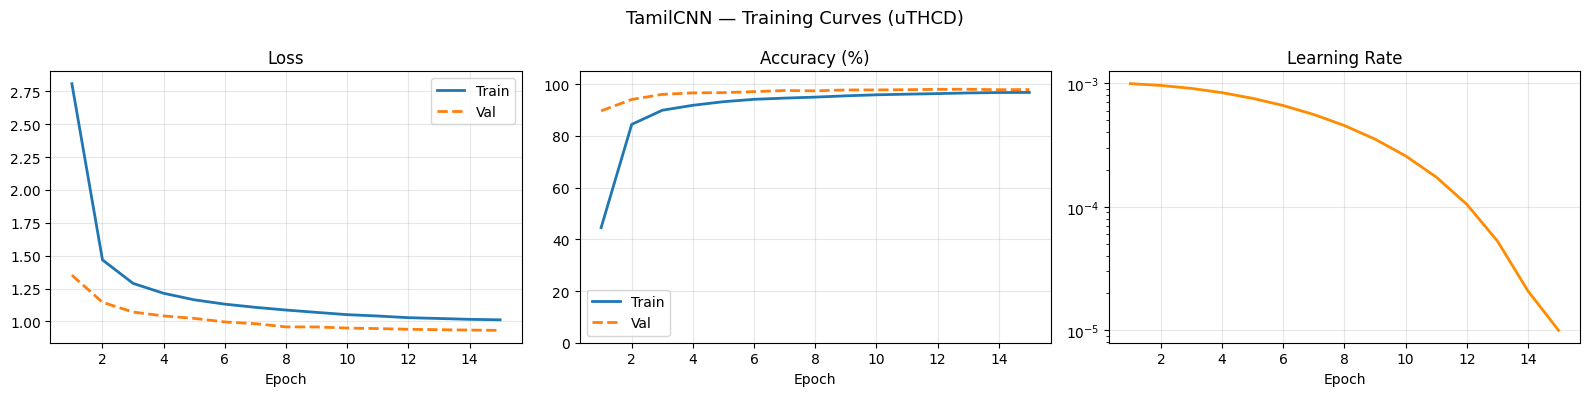

Saved → plots/training_curves.png


In [12]:
ep = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
axes[0].plot(ep, history['train_loss'], label='Train', lw=2)
axes[0].plot(ep, history['val_loss'],   label='Val',   lw=2, ls='--')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(ep, [a*100 for a in history['train_acc']], label='Train', lw=2)
axes[1].plot(ep, [a*100 for a in history['val_acc']],   label='Val',   lw=2, ls='--')
axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(alpha=0.3); axes[1].set_ylim([0, 105])

# Learning rate
axes[2].plot(ep, history['lr'], color='darkorange', lw=2)
axes[2].set_title('Learning Rate'); axes[2].set_xlabel('Epoch')
axes[2].set_yscale('log'); axes[2].grid(alpha=0.3)

fig.suptitle('TamilCNN — Training Curves (uTHCD)', fontsize=13)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → plots/training_curves.png')

## 12. Test Set Evaluation

In [13]:
# Load best checkpoint
ckpt = torch.load(SAVE_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
print(f"Loaded best model from epoch {ckpt['epoch']}  "
      f"(val_acc = {ckpt['val_acc']:.2%})")

_, test_acc, test_preds, test_labels, test_probs = evaluate(
    model, test_loader, criterion
)

# Top-1 and Top-5 accuracy
top1 = test_acc
top5 = top_k_accuracy_score(test_labels, test_probs, k=5,
                              labels=list(range(NUM_CLASSES)))

print(f"\n{'='*40}")
print(f"  Test Top-1 Accuracy : {top1:.2%}")
print(f"  Test Top-5 Accuracy : {top5:.2%}")
print(f"{'='*40}")

Loaded best model from epoch 13  (val_acc = 98.07%)

  Test Top-1 Accuracy : 97.77%
  Test Top-5 Accuracy : 99.87%


## 13. Classification Report

In [14]:
# Full per-class report (156 rows)
target_names = [f"{LABEL_MAP[i]} (C{i+1:03d})" for i in range(NUM_CLASSES)]

report = classification_report(
    test_labels, test_preds,
    target_names=target_names,
    digits=3
)
print(report)

# Save to file
report_path = Path("/kaggle/working/classification_report.txt")
report_path.write_text(report)
print(f"\nFull report saved → {report_path}")

# ── Per-class summary (sorted by F1, worst 20) ───────────────────────────
from sklearn.metrics import classification_report as cr
cr_dict = cr(test_labels, test_preds, output_dict=True)
per_class = [
    {
        'class': i,
        'char' : LABEL_MAP[i],
        'precision': cr_dict.get(str(i), {}).get('precision', 0),
        'recall'   : cr_dict.get(str(i), {}).get('recall',    0),
        'f1'       : cr_dict.get(str(i), {}).get('f1-score',  0),
        'support'  : cr_dict.get(str(i), {}).get('support',   0),
    }
    for i in range(NUM_CLASSES)
]
df_cls = pd.DataFrame(per_class).sort_values('f1')
print("\n── 20 hardest classes (lowest F1) ──")
print(df_cls.head(20).to_string(index=False))

              precision    recall  f1-score   support

    அ (C001)      0.982     0.931     0.956        58
    ஆ (C002)      1.000     1.000     1.000        55
    இ (C003)      1.000     1.000     1.000        56
    ஈ (C004)      0.966     1.000     0.982        56
    உ (C005)      1.000     1.000     1.000        56
    ஊ (C006)      1.000     1.000     1.000        56
    எ (C007)      1.000     1.000     1.000        56
    ஏ (C008)      0.932     0.982     0.957        56
    ஐ (C009)      0.982     1.000     0.991        56
    ஒ (C010)      1.000     0.964     0.982        56
    ஓ (C011)      0.931     0.964     0.947        56
    ஔ (C012)      0.947     0.964     0.956        56
    க (C013)      1.000     1.000     1.000        56
    ங (C014)      1.000     1.000     1.000        56
    ச (C015)      1.000     1.000     1.000        56
    ஞ (C016)      0.933     1.000     0.966        56
    ட (C017)      0.981     0.946     0.964        56
    ண (C018)      1.000    

## 14. Confusion Matrix

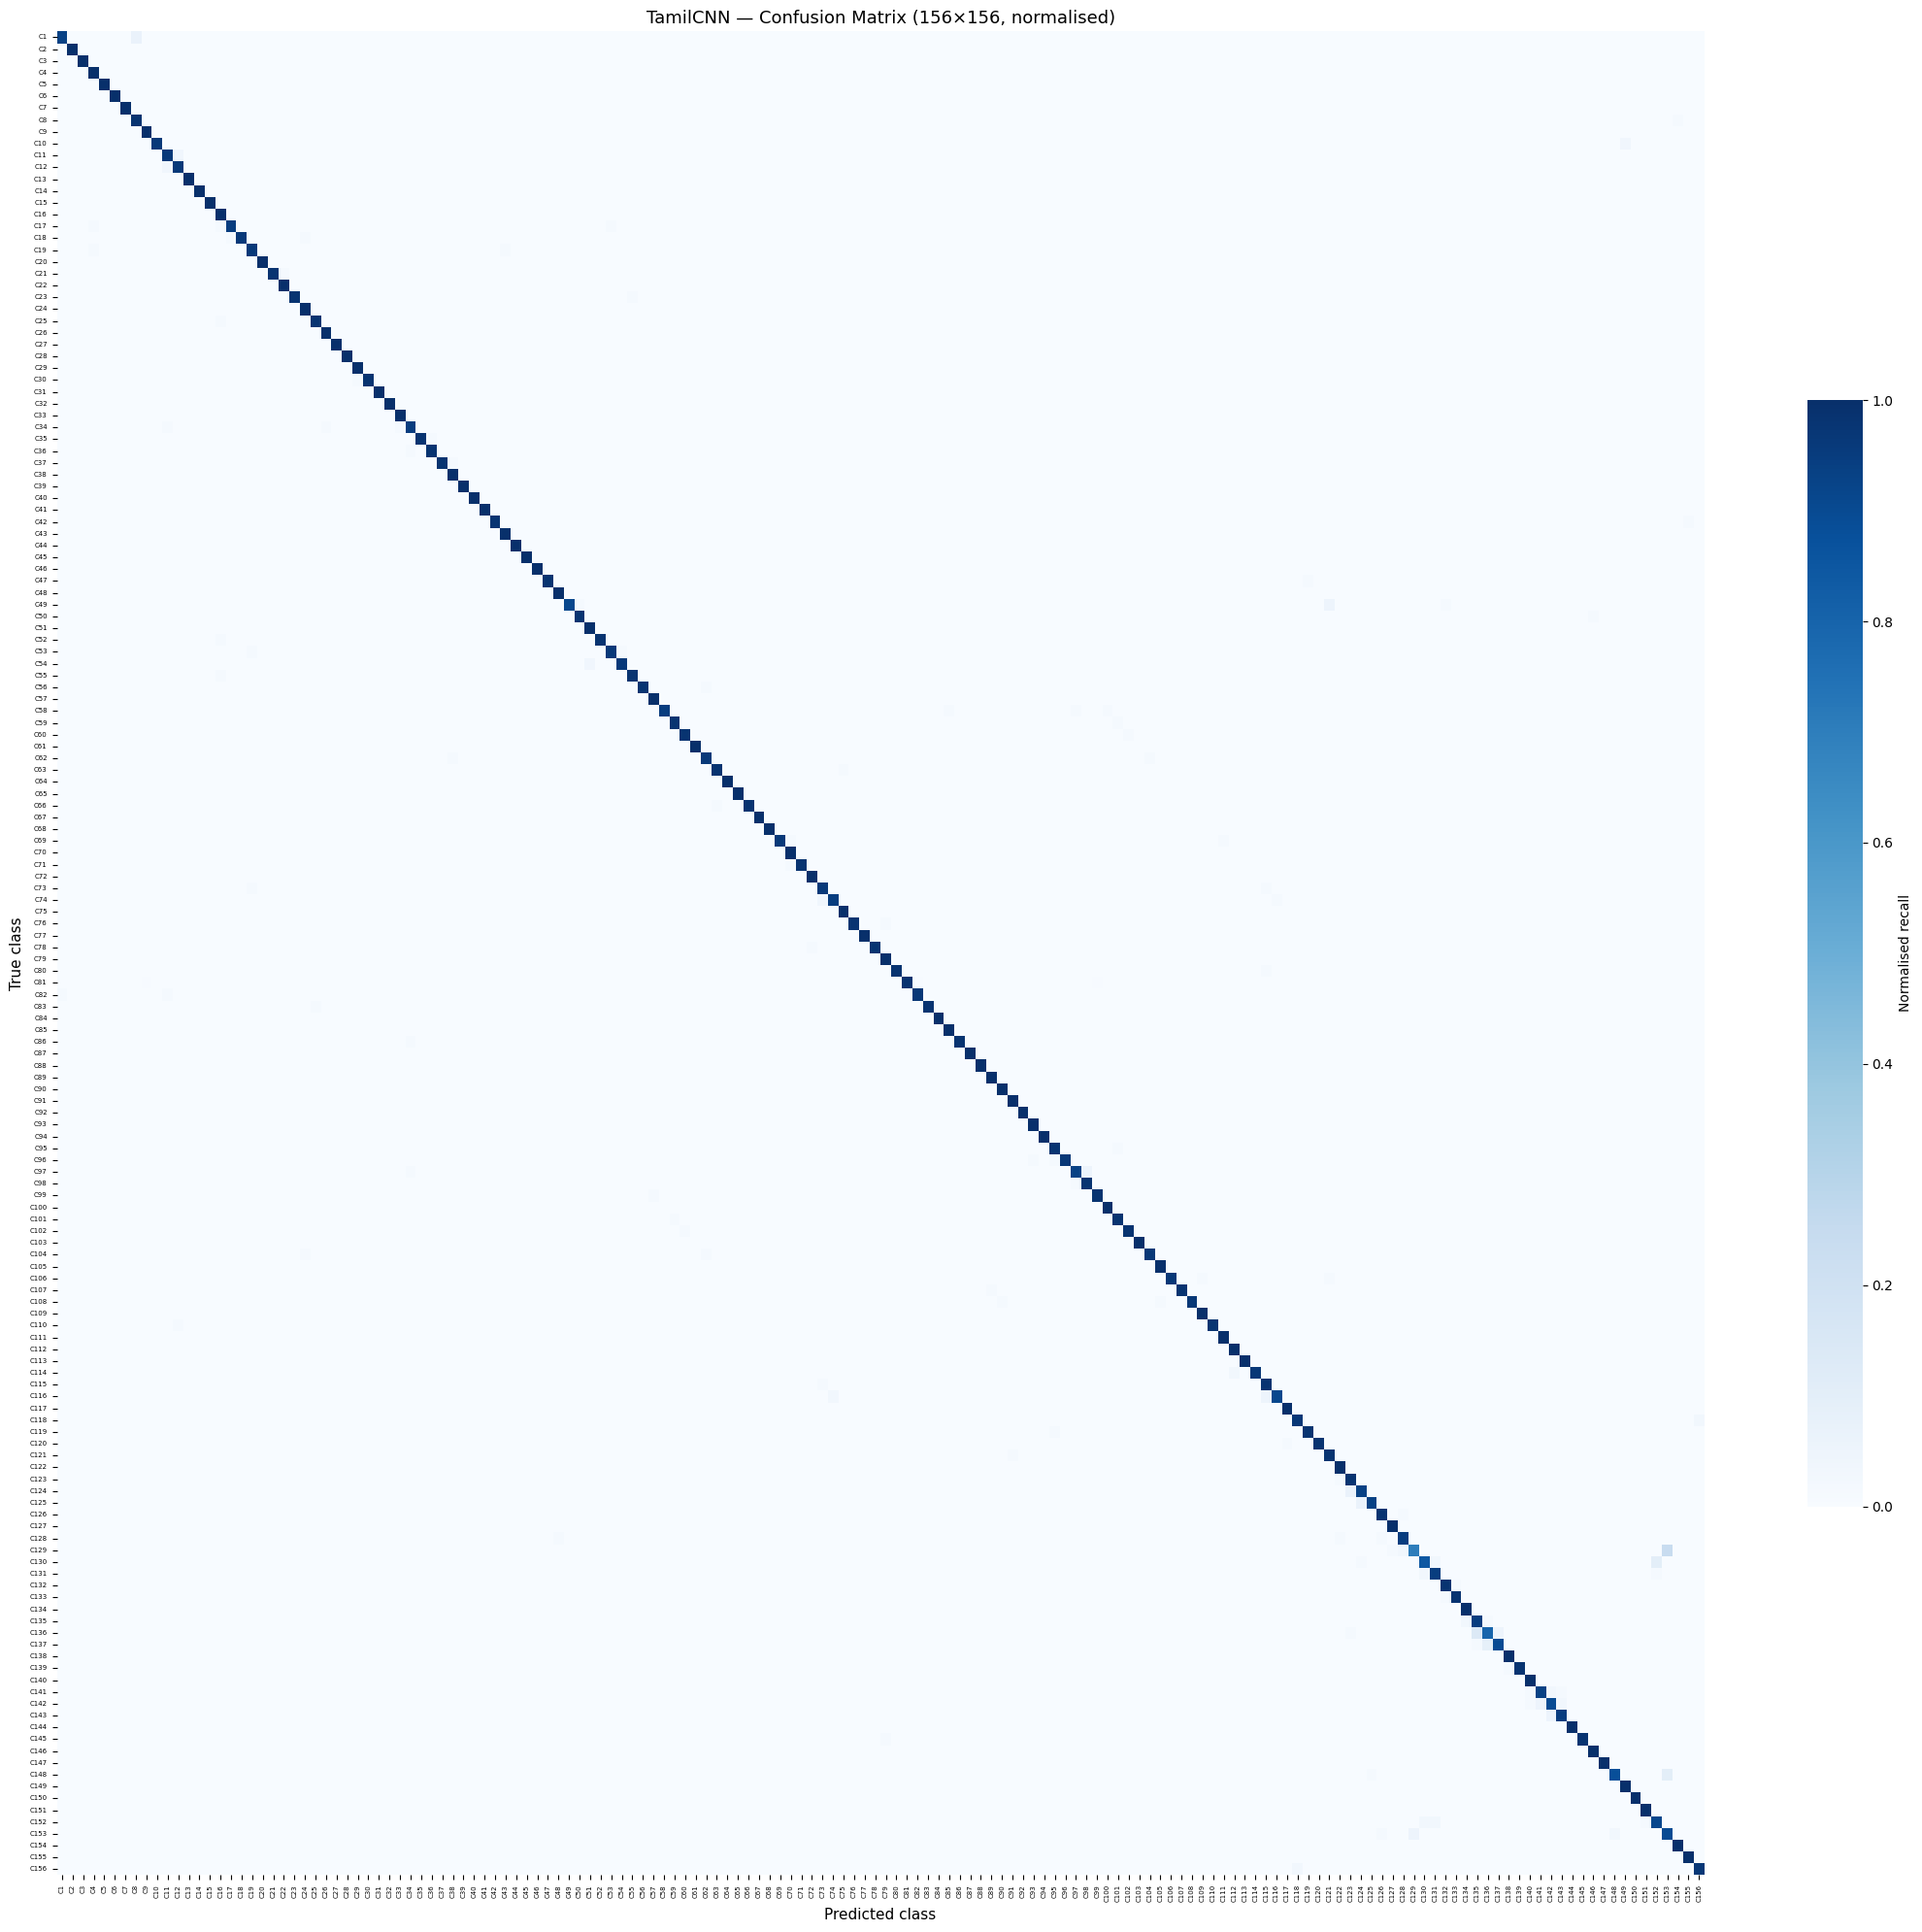

Saved → plots/confusion_matrix_full.png


In [15]:
cm = confusion_matrix(test_labels, test_preds, labels=list(range(NUM_CLASSES)))

# ── Full 156×156 heatmap (normalised) ────────────────────────────────────
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(22, 20))
sns.heatmap(
    cm_norm, ax=ax,
    cmap='Blues', vmin=0, vmax=1,
    xticklabels=[f"C{i+1}" for i in range(NUM_CLASSES)],
    yticklabels=[f"C{i+1}" for i in range(NUM_CLASSES)],
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "Normalised recall"}
)
ax.set_xlabel("Predicted class", fontsize=11)
ax.set_ylabel("True class",      fontsize=11)
ax.set_title("TamilCNN — Confusion Matrix (156×156, normalised)", fontsize=13)
ax.tick_params(axis='both', labelsize=5)

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'confusion_matrix_full.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → plots/confusion_matrix_full.png')

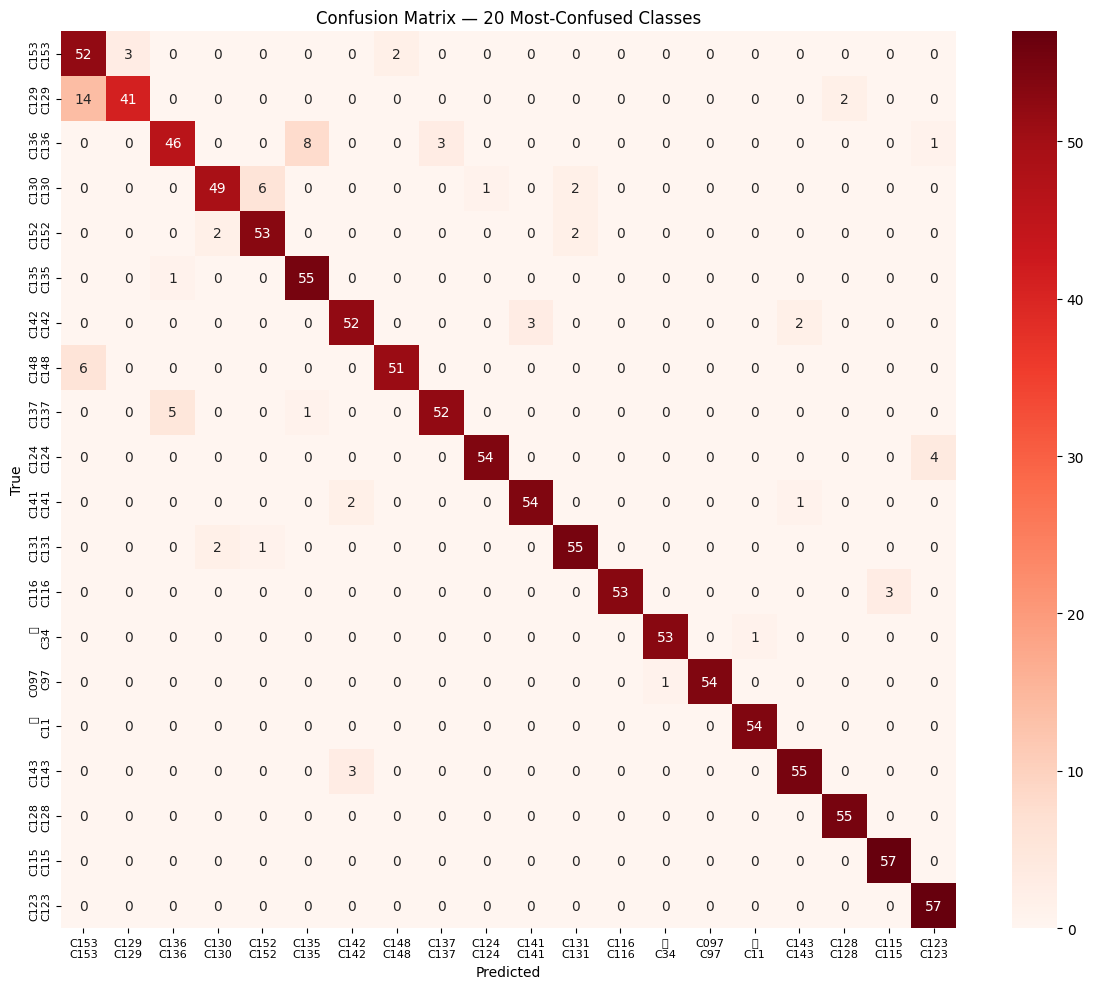

Saved → plots/confusion_matrix_worst20.png


In [16]:
# ── Zoomed: worst 20 classes (most confused) ─────────────────────────────
worst20 = df_cls.head(20)['class'].tolist()

cm_sub  = cm[np.ix_(worst20, worst20)]
labels20 = [f"{LABEL_MAP[i]}\nC{i+1}" for i in worst20]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    cm_sub, ax=ax, annot=True, fmt='d', cmap='Reds',
    xticklabels=labels20, yticklabels=labels20
)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Confusion Matrix — 20 Most-Confused Classes")
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'confusion_matrix_worst20.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved → plots/confusion_matrix_worst20.png')

## 15. Per-Class Accuracy Bar Chart

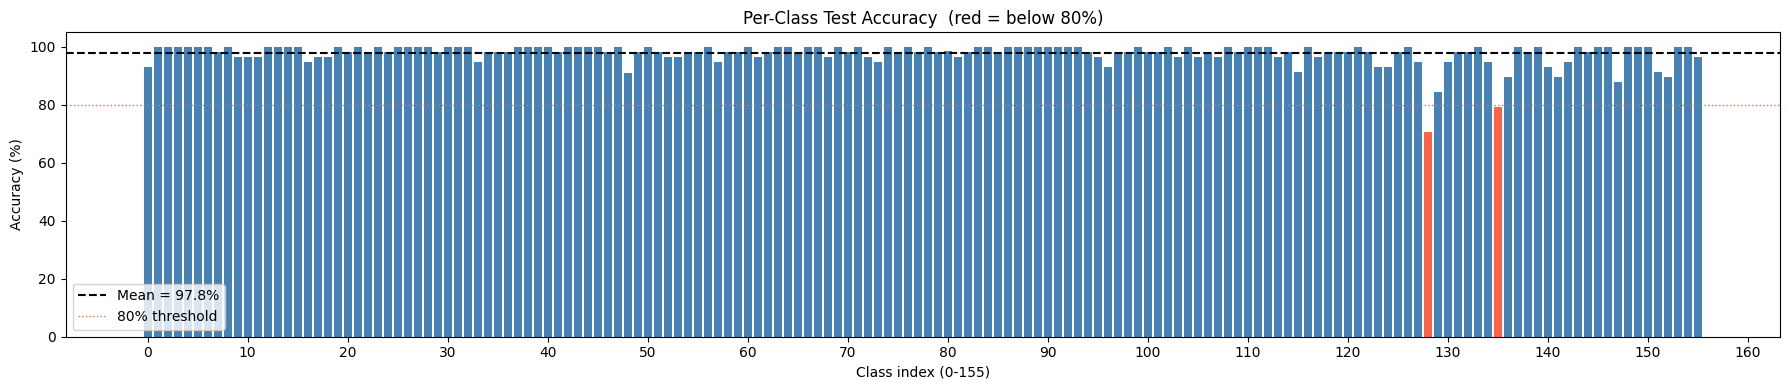

Classes below 80% accuracy: 2 / 156
Saved → plots/per_class_accuracy.png


In [17]:
per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)

fig, ax = plt.subplots(figsize=(18, 4))
colors  = ['tomato' if a < 0.80 else 'steelblue' for a in per_class_acc]
ax.bar(range(NUM_CLASSES), per_class_acc * 100, color=colors, width=0.8)
ax.axhline(per_class_acc.mean() * 100, color='black', lw=1.5, ls='--',
           label=f'Mean = {per_class_acc.mean()*100:.1f}%')
ax.axhline(80, color='tomato', lw=1, ls=':', label='80% threshold')
ax.set_xlabel('Class index (0-155)')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Per-Class Test Accuracy  (red = below 80%)')
ax.set_ylim([0, 105])
ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'per_class_accuracy.png', dpi=120, bbox_inches='tight')
plt.show()

below80 = (per_class_acc < 0.80).sum()
print(f"Classes below 80% accuracy: {below80} / {NUM_CLASSES}")
print('Saved → plots/per_class_accuracy.png')

## 16. Misclassification Visualisation

Total misclassified: 202 / 9050  (2.2%)


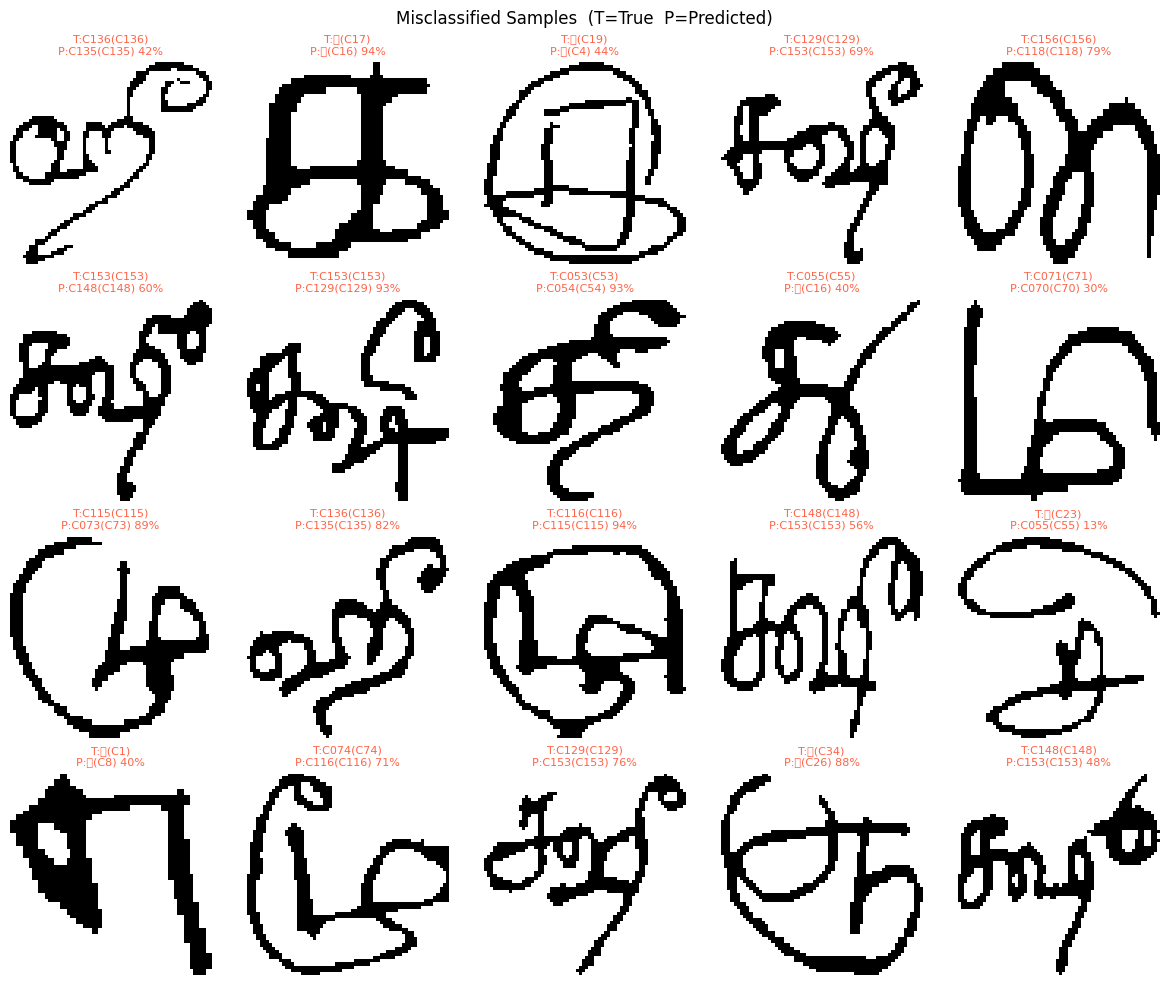

Saved → plots/misclassifications.png


In [18]:
# Show 20 wrong predictions with True vs Predicted labels
wrong_idx = [i for i,(p,t) in enumerate(zip(test_preds, test_labels)) if p != t]
print(f"Total misclassified: {len(wrong_idx)} / {len(test_labels)}  "
      f"({len(wrong_idx)/len(test_labels):.1%})")

sample_wrong = random.sample(wrong_idx, min(20, len(wrong_idx)))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
fig.suptitle('Misclassified Samples  (T=True  P=Predicted)', fontsize=12)

for ax, idx in zip(axes.flat, sample_wrong):
    true_cls = test_labels[idx]
    pred_cls = test_preds[idx]
    conf     = test_probs[idx][pred_cls]
    ax.imshow(x_test[idx], cmap='gray', vmin=0, vmax=255)
    ax.set_title(
        f"T:{LABEL_MAP[true_cls]}(C{true_cls+1})\n"
        f"P:{LABEL_MAP[pred_cls]}(C{pred_cls+1}) {conf:.0%}",
        fontsize=8, color='tomato'
    )
    ax.axis('off')

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'misclassifications.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → plots/misclassifications.png')

## 17. Save History & Summary

In [19]:
summary = {
    'dataset'        : f'uTHCD_{SPLIT}',
    'num_classes'    : NUM_CLASSES,
    'train_samples'  : len(train_ds),
    'val_samples'    : len(val_ds),
    'test_samples'   : len(test_ds),
    'epochs_trained' : EPOCHS,
    'best_val_acc'   : round(best_val, 4),
    'test_top1_acc'  : round(top1, 4),
    'test_top5_acc'  : round(top5, 4),
    'model_params'   : n_param,
    'history'        : history,
}

summary_path = Path('/kaggle/working/training_summary.json')
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)

print('\n' + '='*45)
print('   FINAL RESULTS')
print('='*45)
print(f"   Dataset        : uTHCD_{SPLIT}")
print(f"   Classes        : {NUM_CLASSES}")
print(f"   Model params   : {n_param:,}")
print(f"   Best val acc   : {best_val:.2%}")
print(f"   Test Top-1 acc : {top1:.2%}")
print(f"   Test Top-5 acc : {top5:.2%}")
print('='*45)

print('\nAll output files:')
for p in sorted(Path('/kaggle/working').rglob('*')):
    if p.is_file():
        size = p.stat().st_size / 1024
        print(f"  {str(p.relative_to('/kaggle/working')):50s} {size:7.1f} KB")


   FINAL RESULTS
   Dataset        : uTHCD_b
   Classes        : 156
   Model params   : 1,385,212
   Best val acc   : 98.07%
   Test Top-1 acc : 97.77%
   Test Top-5 acc : 99.87%

All output files:
  .virtual_documents/__notebook_source__.ipynb          24.7 KB
  classification_report.txt                              8.5 KB
  models/tamil_cnn_best.pth                          16293.6 KB
  plots/class_distribution.png                          33.6 KB
  plots/confusion_matrix_full.png                      171.0 KB
  plots/confusion_matrix_worst20.png                    97.6 KB
  plots/misclassifications.png                          64.4 KB
  plots/per_class_accuracy.png                          41.2 KB
  plots/sample_images.png                               48.8 KB
  plots/training_curves.png                             68.9 KB
  training_summary.json                                  2.3 KB
